# 01 - Tiền xử lý và chia dữ liệu

- chạy `python src/prepare_data.py`, kết quả `data/processed/...`
- đọc và thống kê dữ liệu đã xử lý

In [1]:
import re, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

from src.config import (LABELS, DATA_DIR)
print("ROOT =", ROOT)

ROOT = c:\Users\this pc\Downloads\7_projectNLP


## 1. Kiểm tra dữ liệu đã chia

In [2]:
split_files = [DATA_DIR / f"{s}.csv" for s in ("train", "val", "test")]
assert all(f.exists() for f in split_files), "Chưa tiền xử lý và chia tập"
print("Đã có đủ train/val/test.csv")

Đã có đủ train/val/test.csv


## 2. Dữ liệu thô `data/raw/dataset.xlsx` 

In [3]:
raw = pd.read_excel(ROOT / "data" / "raw" / "dataset.xlsx", sheet_name=None)
rows = []

for name, part in raw.items():
    vc = part["label_id"].value_counts()
    rows.append({
        "sheet": name,
        "số dòng": len(part),
        "thiếu text/nhãn": int(part[["free_text", "label_id"]].isna().any(axis=1).sum()),
        **{LABELS[i]: int(vc.get(i,0)) for i in LABELS}
    })

raw_table = pd.DataFrame(rows)
raw_table.loc[len(raw_table)] = ["TỔNG", *raw_table.iloc[:, 1:].sum().tolist()]
display(raw_table)

,sheet,số dòng,thiếu text/nhãn,BÌNH THƯỜNG,XÚC PHẠM,THÙ GHÉT
0,train,24767,724,19883,1606,2556
1,validation,2672,0,2190,212,270
2,test,6691,11,5548,444,688
3,TỔNG,34130,735,27621,2262,3514


## 3. Khử trùng lặp dữ liệu trên dữ liệu gốc

In [4]:
sys.path.insert(0, str(ROOT / "src"))
import prepare_data as pdata

df_all = pdata.load_raw()
df_dedup = pdata.deduplicate(df_all)
n_final = sum(len(pd.read_csv(f)) for f in split_files)

Sheet train: 24767
Sheet validation: 2672
Sheet test: 6691
Gộp các sheet: 34130
Sau khi bỏ dòng thiếu text/nhãn: 33395
Sau khi khử trùng lặp: 30286


## 4. Phân bố nhãn theo tập

,train,val,test
label_id,,,
BÌNH THƯỜNG,19991,2474,2458
XÚC PHẠM,1615,202,201
THÙ GHÉT,2610,327,326
TỔNG,24216,3003,2985


Tỉ lệ (%) theo từng tập:


,train,val,test
label_id,,,
BÌNH THƯỜNG,82.55,82.38,82.35
XÚC PHẠM,6.67,6.73,6.73
THÙ GHÉT,10.78,10.89,10.92


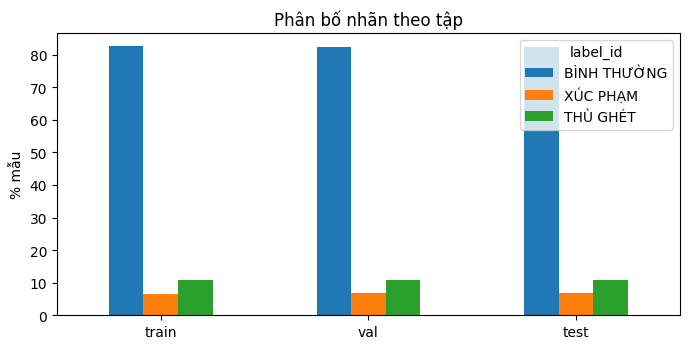

In [7]:
splits = {s: pd.read_csv(DATA_DIR / f"{s}.csv") for s in ("train", "val", "test")}
counts_dict = {}

for s, d in splits.items():
    counts_dict[s] = d["label_id"].map(LABELS).value_counts()

tab = pd.DataFrame(counts_dict).reindex(list(LABELS.values()))
tab.loc["TỔNG"] = tab.sum()
pct = (tab.drop("TỔNG") / tab.loc["TỔNG"] * 100).round(2)
display(tab)
print("Tỉ lệ (%) theo từng tập:")
display(pct)

fig, ax = plt.subplots(figsize=(7, 3.6))
pct.T.plot.bar(ax=ax, rot=0)
ax.set_ylabel("% mẫu")
ax.set_title("Phân bố nhãn theo tập")
plt.tight_layout()
plt.show()

In [8]:
# trùng chữ giữa các tập sau khi tiền xử lý (khử trùng ban đầu dựa trên văn bản gốc nên vẫn có thể còn sót)
rows = []
for c in ["text_baseline", "text_phobert", "text_visobert"]:
    a, b, d = (set(splits[s][c].fillna("")) for s in ("train", "val", "test"))
    rows.append({"cột": c, "train và val": len(a & b), "train và test": len(a & d), "val và test": len(b & d)})
display(pd.DataFrame(rows))

,cột,train và val,train và test,val và test
0,text_baseline,0,0,0
1,text_phobert,0,0,0
2,text_visobert,0,0,0
